# E-commerce Customer Analytics: SQL, Segmentation, Retention and Forecasting
**Author:** Apara Bhargava · **Tools:** SQL (SQLite), Python (pandas, scikit-learn, statsmodels, matplotlib) in Google Colab

**Question:** For an online retailer, who are the valuable customers, how many come back, and what will sales be over the next 6 months?

**Data (real, public):** *Online Retail II*, UCI Machine Learning Repository. About 1 million transactions from a UK-based online retailer selling giftware, Dec 2009 to Dec 2011. Licence: CC BY 4.0.
Citation: Chen, D. (2012). *Online Retail II* [Dataset]. UCI Machine Learning Repository. https://doi.org/10.24432/C5CG6D

*How to run: Runtime → Run all. Each step explains the business idea first, then the code line by line.*

## Step 1: Tools
- `sqlite3`: a small SQL database that runs inside Python, so there is nothing to install
- `pandas`, `numpy`, `matplotlib`: data tables, maths, charts
- `scikit-learn`: machine learning (k-means clustering)
- `statsmodels`: time-series forecasting

In [1]:
import pandas as pd                       # data tables
import numpy as np                        # maths
import matplotlib.pyplot as plt           # charts
import sqlite3                            # SQL database inside Python
from sklearn.preprocessing import StandardScaler   # puts variables on the same scale
from sklearn.cluster import KMeans                 # k-means clustering
from sklearn.metrics import silhouette_score       # measures how well clusters separate
import warnings; warnings.filterwarnings('ignore') # hide routine warning messages

pd.set_option('display.float_format', lambda x: f'{x:,.2f}')
print('Tools loaded')

Tools loaded


## Step 2: Download the data from the UCI repository
The file has two sheets: 2009-2010 and 2010-2011. Reading it takes about 2 minutes.

In [2]:
!wget -q -O online_retail_ii.zip "https://archive.ics.uci.edu/static/public/502/online+retail+ii.zip"
!unzip -o -q online_retail_ii.zip

import glob
path = glob.glob('*.xlsx')[0]                                      # the Excel file from the zip
sheets = pd.read_excel(path, sheet_name=None)                        # None = read every sheet
raw = pd.concat(sheets.values(), ignore_index=True)                 # stack the two sheets
raw.columns = ['Invoice', 'StockCode', 'Description', 'Quantity', 'InvoiceDate', 'Price', 'CustomerID', 'Country']
print(f'{len(raw):,} rows | {raw.InvoiceDate.min().date()} to {raw.InvoiceDate.max().date()}')
raw.head()

1,067,371 rows | 2009-12-01 to 2011-12-09


,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,CustomerID,Country
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,6.95,"13,085.00",United Kingdom
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,"13,085.00",United Kingdom
2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,"13,085.00",United Kingdom
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,2009-12-01 07:45:00,2.10,"13,085.00",United Kingdom
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,2009-12-01 07:45:00,1.25,"13,085.00",United Kingdom


## Step 3: Data quality checks
Real data is messy. Before any analysis we check, then clean:
1. **Missing customer IDs**: we cannot track a customer without an ID
2. **Cancellations**: invoice numbers starting with **C** are returns or cancellations
3. **Zero or negative prices**, and non-product lines (postage, bank charges, manual adjustments)
4. **Duplicate rows**
5. **Partial months**: the data ends on 9 Dec 2011, so December 2011 is incomplete

In [3]:
df = raw.copy()
df['Invoice'] = df['Invoice'].astype(str)
df['StockCode'] = df['StockCode'].astype(str)
df['IsCancel'] = df['Invoice'].str.startswith('C')                      # True for cancellation invoices
NON_PRODUCT = ['POST', 'DOT', 'M', 'C2', 'D', 'BANK CHARGES', 'AMAZONFEE', 'CRUK', 'PADS', 'TEST001', 'TEST002', 'ADJUST', 'ADJUST2', 'S', 'B', 'SP1002', 'GIFT']
df['IsNonProduct'] = df['StockCode'].str.upper().isin(NON_PRODUCT)

checks = pd.Series({
    'Total rows': len(df),
    'Rows with no customer ID': df['CustomerID'].isna().sum(),
    'Cancellation rows (invoice starts with C)': df['IsCancel'].sum(),
    'Rows with price <= 0': (df['Price'] <= 0).sum(),
    'Non-product rows (postage, fees, adjustments)': df['IsNonProduct'].sum(),
    'Exact duplicate rows': df.duplicated().sum(),
})
print(checks.apply(lambda x: f'{x:,}').to_string())

# Clean sales table: real customers, real products, positive quantity and price, no duplicates
sales = df[(~df['IsCancel']) & (~df['IsNonProduct']) & df['CustomerID'].notna() &
           (df['Quantity'] > 0) & (df['Price'] > 0)].drop_duplicates().copy()
sales['CustomerID'] = sales['CustomerID'].astype(int)
sales['Revenue'] = sales['Quantity'] * sales['Price']                   # line value in GBP
sales['Month'] = sales['InvoiceDate'].dt.to_period('M').astype(str)

# Returns table: cancellation lines with a customer ID (used for return rates)
returns_tbl = df[df['IsCancel'] & df['CustomerID'].notna() & (~df['IsNonProduct'])].copy()
returns_tbl['ReturnValue'] = -(returns_tbl['Quantity'] * returns_tbl['Price'])

print(f'\nClean sales rows: {len(sales):,} ({len(sales)/len(df):.0%} of raw) | customers: {sales.CustomerID.nunique():,} | invoices: {sales.Invoice.nunique():,}')
print(f'Total clean revenue: £{sales.Revenue.sum():,.0f}')
assert (sales['Revenue'] > 0).all(), 'CHECK: negative revenue left in the clean table'
print('Check passed: every clean line has positive revenue')

Total rows                                       1,067,371
Rows with no customer ID                           243,007
Cancellation rows (invoice starts with C)           19,494
Rows with price <= 0                                 6,207
Non-product rows (postage, fees, adjustments)        5,834
Exact duplicate rows                                34,335

Clean sales rows: 776,577 (73% of raw) | customers: 5,852 | invoices: 36,594
Total clean revenue: £17,068,568
Check passed: every clean line has positive revenue


## Step 4: SQL analysis
We load the clean tables into a SQL database and answer business questions with **SQL queries**, the language analysts use to pull data from company databases.

Each query below: **SELECT** chooses columns, **FROM** the table, **WHERE** filters rows, **GROUP BY** makes one row per group, **ORDER BY** sorts, **LIMIT** keeps the top rows.

In [4]:
con = sqlite3.connect(':memory:')                                     # a database in memory
sales.assign(InvoiceDate=sales['InvoiceDate'].astype(str)).to_sql('sales', con, index=False)
returns_tbl.assign(InvoiceDate=returns_tbl['InvoiceDate'].astype(str)).to_sql('returns', con, index=False)

def sql(query):                        # helper: run a query, return a pandas table
    return pd.read_sql_query(query, con)
print('Tables loaded:', sql("SELECT name FROM sqlite_master WHERE type='table'").name.tolist())

Tables loaded: ['sales', 'returns']


### Query 1: Monthly revenue, orders, customers and average order value

In [5]:
monthly = sql('''
SELECT Month,
       ROUND(SUM(Revenue), 0)                       AS revenue,
       COUNT(DISTINCT Invoice)                      AS orders,
       COUNT(DISTINCT CustomerID)                   AS customers,
       ROUND(SUM(Revenue) / COUNT(DISTINCT Invoice), 2) AS avg_order_value
FROM sales
GROUP BY Month
ORDER BY Month
''')
monthly

,Month,revenue,orders,customers,avg_order_value
0,2009-12,"677,916.00",1497,951,452.85
1,2010-01,"533,713.00",959,701,556.53
2,2010-02,"497,938.00",1093,771,455.57
3,2010-03,"665,974.00",1509,1051,441.33
4,2010-04,"585,127.00",1315,939,444.96
5,2010-05,"592,734.00",1365,965,434.24
6,2010-06,"628,809.00",1479,1034,425.16
7,2010-07,"581,488.00",1362,924,426.94
8,2010-08,"594,561.00",1276,910,465.96
9,2010-09,"805,545.00",1659,1136,485.56


### Query 2: Top 10 products by revenue

In [6]:
top_products = sql('''
SELECT StockCode, MAX(Description) AS product,
       ROUND(SUM(Revenue), 0) AS revenue,
       SUM(Quantity)          AS units,
       COUNT(DISTINCT CustomerID) AS customers
FROM sales
GROUP BY StockCode
ORDER BY revenue DESC
LIMIT 10
''')
top_products['share_of_total'] = top_products['revenue'] / sales['Revenue'].sum()
top_products

,StockCode,product,revenue,units,customers,share_of_total
0,22423,REGENCY CAKESTAND 3 TIER,"277,656.00",24124,1314,0.02
1,85123A,WHITE HANGING HEART T-LIGHT HOLDER,"247,203.00",91814,1490,0.01
2,23843,"PAPER CRAFT , LITTLE BIRDIE","168,470.00",80995,1,0.01
3,85099B,RED RETROSPOT JUMBO BAG,"167,921.00",93436,978,0.01
4,84879,ASSORTED COLOUR BIRD ORNAMENT,"124,352.00",78234,1010,0.01
5,47566,PARTY BUNTING,"103,283.00",23460,894,0.01
6,23166,MEDIUM CERAMIC TOP STORAGE JAR,"81,417.00",77916,138,0.00
7,22086,PAPER CHAIN KIT 50'S CHRISTMAS,"76,598.00",28380,896,0.00
8,79321,CHILLI LIGHTS,"69,084.00",14843,304,0.00
9,22386,JUMBO BAG PINK WITH WHITE SPOTS,"67,770.00",37338,601,0.00


### Query 3: Revenue by country (top 10)

In [7]:
countries = sql('''
SELECT Country, ROUND(SUM(Revenue), 0) AS revenue, COUNT(DISTINCT CustomerID) AS customers
FROM sales
GROUP BY Country
ORDER BY revenue DESC
LIMIT 10
''')
countries['share'] = countries['revenue'] / sales['Revenue'].sum()
countries

,Country,revenue,customers,share
0,United Kingdom,"14,288,759.00",5334,0.84
1,EIRE,"586,626.00",3,0.03
2,Netherlands,"549,773.00",22,0.03
3,Germany,"383,289.00",107,0.02
4,France,"309,403.00",93,0.02
5,Australia,"167,800.00",15,0.01
6,Spain,"97,767.00",38,0.01
7,Switzerland,"93,401.00",22,0.01
8,Sweden,"86,045.00",19,0.01
9,Denmark,"67,423.00",12,0.00


### Query 4: Repeat customers
A **subquery** first counts each customer's orders, then the outer query groups customers into one-time and repeat buyers.

In [8]:
repeat = sql('''
SELECT CASE WHEN n_orders = 1 THEN 'One-time' ELSE 'Repeat (2+ orders)' END AS customer_type,
       COUNT(*)              AS customers,
       ROUND(SUM(spend), 0)  AS revenue
FROM (SELECT CustomerID, COUNT(DISTINCT Invoice) AS n_orders, SUM(Revenue) AS spend
      FROM sales GROUP BY CustomerID)
GROUP BY customer_type
''')
repeat['share_of_customers'] = repeat['customers'] / repeat['customers'].sum()
repeat['share_of_revenue'] = repeat['revenue'] / repeat['revenue'].sum()
repeat

,customer_type,customers,revenue,share_of_customers,share_of_revenue
0,One-time,1618,"556,000.00",0.28,0.03
1,Repeat (2+ orders),4234,"16,512,568.00",0.72,0.97


### Query 5: Return rates
A **JOIN** combines the returns table with the sales table by product, to compare returned value with sold value.

In [9]:
ret_rate = sql('''
SELECT s.StockCode, MAX(s.Description) AS product,
       ROUND(SUM(s.Revenue), 0)                  AS sold_value,
       ROUND(COALESCE(MAX(r.returned), 0), 0)     AS returned_value,
       ROUND(COALESCE(MAX(r.returned), 0) / SUM(s.Revenue), 4) AS return_rate
FROM sales s
LEFT JOIN (SELECT StockCode, SUM(ReturnValue) AS returned FROM returns GROUP BY StockCode) r
       ON s.StockCode = r.StockCode
GROUP BY s.StockCode
HAVING SUM(s.Revenue) > 20000                  -- only products with meaningful sales
ORDER BY return_rate DESC
LIMIT 10
''')
overall_return_rate = returns_tbl['ReturnValue'].sum() / sales['Revenue'].sum()
print(f'Overall returned value as % of sold value: {overall_return_rate:.1%}')
ret_rate

Overall returned value as % of sold value: 4.2%


,StockCode,product,sold_value,returned_value,return_rate
0,23843,"PAPER CRAFT , LITTLE BIRDIE","168,470.00","168,470.00",1.00
1,23166,MEDIUM CERAMIC TOP STORAGE JAR,"81,417.00","77,480.00",0.95
2,21108,FAIRY CAKE FLANNEL ASSORTED COLOUR,"23,323.00","6,614.00",0.28
3,47566B,TEA TIME PARTY BUNTING,"24,255.00","4,491.00",0.19
4,20971,PINK BLUE FELT CRAFT TRINKET BOX,"23,554.00","4,113.00",0.17
5,71477,COLOURED GLASS STAR T-LIGHT HOLDER,"43,297.00","7,174.00",0.17
6,84078A,SET/4 WHITE RETRO STORAGE CUBES,"36,260.00","5,188.00",0.14
7,48185,DOORMAT FAIRY CAKE,"39,465.00","4,679.00",0.12
8,21314,SMALL GLASS HEART TRINKET POT,"20,588.00","2,303.00",0.11
9,37449,CERAMIC CAKE STAND + HANGING CAKES,"20,205.00","2,244.00",0.11


### Query 6: Top products net of returns
Query 5 showed that two products had almost all of their sales cancelled: single bulk orders that were reversed. Ranking products by sales **after** subtracting returns gives a truer picture.

In [10]:
top_net = sql('''
SELECT s.StockCode, MAX(s.Description) AS product,
       ROUND(SUM(s.Revenue), 0)                                AS sold_value,
       ROUND(COALESCE(MAX(r.returned), 0), 0)                  AS returned_value,
       ROUND(SUM(s.Revenue) - COALESCE(MAX(r.returned), 0), 0) AS net_revenue
FROM sales s
LEFT JOIN (SELECT StockCode, SUM(ReturnValue) AS returned FROM returns GROUP BY StockCode) r
       ON s.StockCode = r.StockCode
GROUP BY s.StockCode
ORDER BY net_revenue DESC
LIMIT 10
''')
top_net

,StockCode,product,sold_value,returned_value,net_revenue
0,22423,REGENCY CAKESTAND 3 TIER,"277,656.00","16,750.00","260,907.00"
1,85123A,WHITE HANGING HEART T-LIGHT HOLDER,"247,203.00","9,372.00","237,831.00"
2,85099B,RED RETROSPOT JUMBO BAG,"167,921.00","2,176.00","165,744.00"
3,84879,ASSORTED COLOUR BIRD ORNAMENT,"124,352.00",720.00,"123,632.00"
4,47566,PARTY BUNTING,"103,283.00","1,194.00","102,089.00"
5,22086,PAPER CHAIN KIT 50'S CHRISTMAS,"76,598.00","1,227.00","75,371.00"
6,79321,CHILLI LIGHTS,"69,084.00",631.00,"68,454.00"
7,22386,JUMBO BAG PINK WITH WHITE SPOTS,"67,770.00",865.00,"66,905.00"
8,48138,DOORMAT UNION FLAG,"64,270.00",359.00,"63,911.00"
9,85099F,JUMBO BAG STRAWBERRY,"64,128.00",512.00,"63,616.00"


## Step 5: Cohort retention: how many customers come back?
A **cohort** is the group of customers who made their first purchase in the same month. We track what share of each cohort buys again 1, 2, 3... months later.
This is how D2C and subscription businesses measure loyalty.

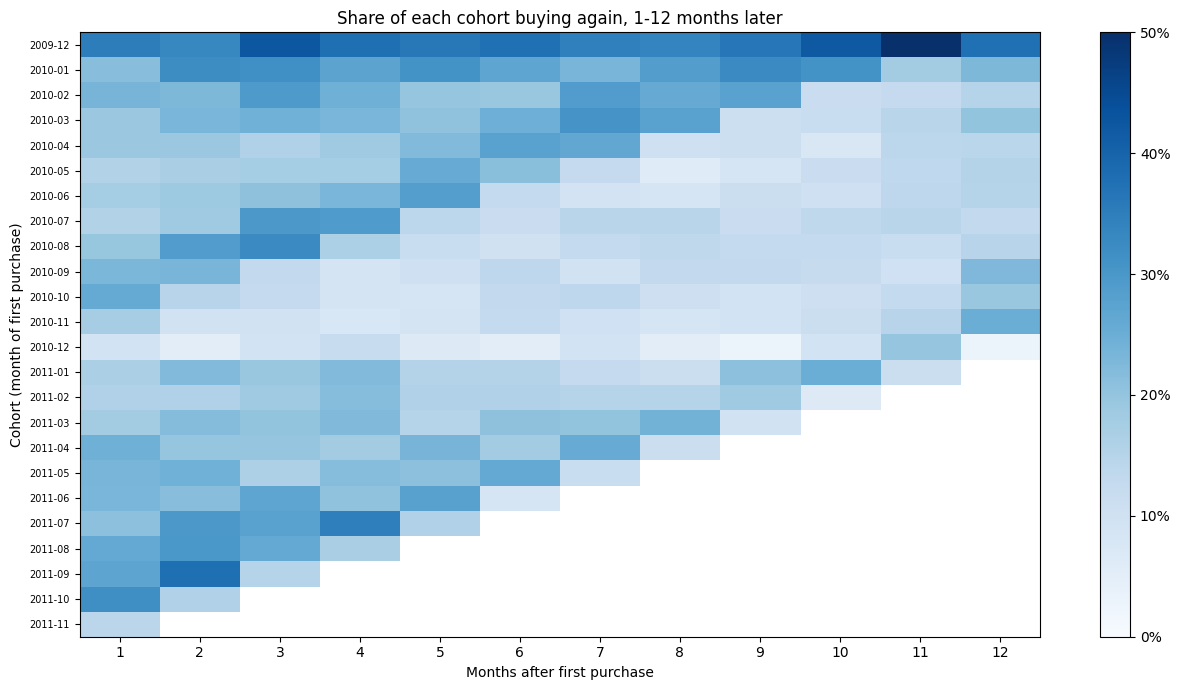

Average retention: month 1: 21.0% | month 3: 21.7% | month 6: 17.9% | month 12: 18.3%
Average monthly repeat purchase rate: 23.9% of past customers


In [11]:
orders = sales.groupby(['CustomerID', 'Month'], as_index=False)['Revenue'].sum()
first = orders.groupby('CustomerID')['Month'].min().rename('Cohort')
orders = orders.join(first, on='CustomerID')
to_num = lambda m: pd.PeriodIndex(m, freq='M').year * 12 + pd.PeriodIndex(m, freq='M').month
orders['MonthsSince'] = to_num(orders['Month']) - to_num(orders['Cohort'])   # 0 = first month

cohort_counts = orders.pivot_table(index='Cohort', columns='MonthsSince', values='CustomerID', aggfunc='nunique')
retention = cohort_counts.div(cohort_counts[0], axis=0)          # share of the cohort still buying
retention = retention.iloc[:-1]                                  # drop the last (partial) cohort

fig, ax = plt.subplots(figsize=(13, 7))
im = ax.imshow(retention.iloc[:, 1:13], cmap='Blues', aspect='auto', vmin=0, vmax=0.5)
ax.set_xticks(range(12)); ax.set_xticklabels(range(1, 13))
ax.set_yticks(range(len(retention))); ax.set_yticklabels(retention.index, fontsize=7)
ax.set_xlabel('Months after first purchase'); ax.set_ylabel('Cohort (month of first purchase)')
ax.set_title('Share of each cohort buying again, 1-12 months later')
plt.colorbar(im, ax=ax, format=plt.FuncFormatter(lambda v, _: f'{v:.0%}'))
plt.tight_layout(); plt.savefig('cohort_retention.png', dpi=150); plt.show()

avg_ret = retention[[1, 3, 6, 12]].mean()
print('Average retention:', ' | '.join(f'month {k}: {v:.1%}' for k, v in avg_ret.items()))

# Monthly repeat purchase rate: of all customers acquired before a month, what share buys in that month?
months = sorted(orders['Month'].unique())[:-1]                    # exclude partial Dec 2011
rows = []
for m in months[1:]:
    past = first[first < m].index                                  # customers acquired before month m
    buyers = orders.loc[orders['Month'] == m, 'CustomerID']
    rows.append({'Month': m, 'Past customers': len(past),
                 'Repeat rate': buyers.isin(past).sum() / len(past)})
repeat_rate = pd.DataFrame(rows).set_index('Month')
print(f"Average monthly repeat purchase rate: {repeat_rate['Repeat rate'].mean():.1%} of past customers")

## Step 6: Customer segmentation with RFM and k-means (machine learning)
**RFM** describes each customer with three numbers:
- **Recency**: days since their last purchase (lower = better)
- **Frequency**: number of orders
- **Monetary**: total spend

**K-means clustering** is an unsupervised machine-learning method: it groups customers so that customers in a group are similar to each other. We log-transform and standardise first, because spend ranges from £1 to £500,000 and would otherwise dominate.

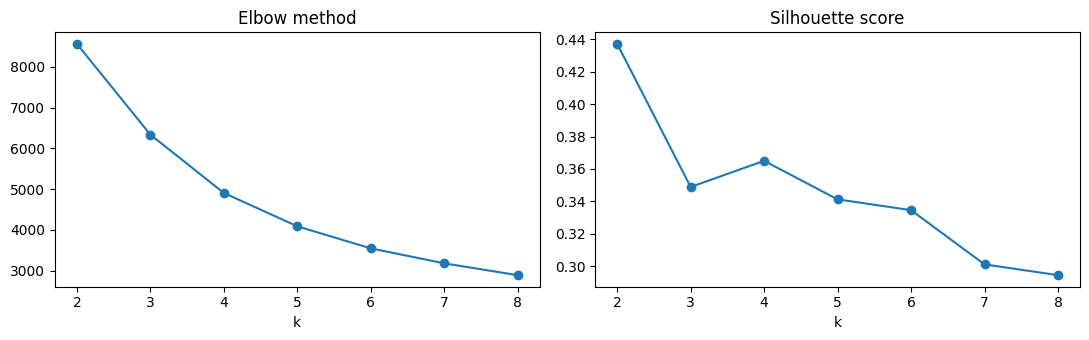

,Inertia (lower = tighter),Silhouette (higher = clearer)
k,,
2,"8,561.59",0.44
3,"6,337.65",0.35
4,"4,907.53",0.36
5,"4,090.11",0.34
6,"3,549.37",0.33
7,"3,182.08",0.30
8,"2,892.13",0.29


In [12]:
snapshot = sales['InvoiceDate'].max() + pd.Timedelta(days=1)          # 'today' = day after the last sale
rfm = sales.groupby('CustomerID').agg(
    Recency=('InvoiceDate', lambda d: (snapshot - d.max()).days),
    Frequency=('Invoice', 'nunique'),
    Monetary=('Revenue', 'sum'))
X = StandardScaler().fit_transform(np.log1p(rfm))                     # log, then scale to mean 0, sd 1

# How many clusters? Try 2-8 and compare two measures
scores = []
for k in range(2, 9):
    km = KMeans(n_clusters=k, n_init=10, random_state=42).fit(X)
    scores.append({'k': k, 'Inertia (lower = tighter)': km.inertia_,
                   'Silhouette (higher = clearer)': silhouette_score(X, km.labels_, sample_size=min(5000, len(X)), random_state=42)})
scores = pd.DataFrame(scores).set_index('k')
fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
scores.iloc[:, 0].plot(ax=ax[0], marker='o', title='Elbow method'); scores.iloc[:, 1].plot(ax=ax[1], marker='o', title='Silhouette score')
plt.tight_layout(); plt.savefig('choosing_k.png', dpi=150); plt.show()
scores

In [13]:
K = 4                                  # 4 segments: a common, easy-to-act-on choice; check the charts above
km = KMeans(n_clusters=K, n_init=10, random_state=42).fit(X)
rfm['Cluster'] = km.labels_

profile = rfm.groupby('Cluster').agg(Customers=('Recency', 'size'), Recency=('Recency', 'median'),
                                     Frequency=('Frequency', 'median'), Monetary=('Monetary', 'median'),
                                     Revenue=('Monetary', 'sum'))
profile['Share of customers'] = profile['Customers'] / profile['Customers'].sum()
profile['Share of revenue'] = profile['Revenue'] / profile['Revenue'].sum()

# Name segments by behaviour (rules applied to each cluster's median R, F, M)
champ = profile['Monetary'].idxmax()                                  # highest spend
lost = profile.drop(champ)['Recency'].idxmax()                        # longest since last purchase
rest = profile.drop([champ, lost]).sort_values('Recency')             # the other two, most recent first
names = {champ: 'Champions', lost: 'Lost / one-off', rest.index[0]: 'Recent, low spend', rest.index[1]: 'Lapsing regulars'}
profile['Segment'] = profile.index.map(names)
rfm['Segment'] = rfm['Cluster'].map(profile['Segment'])
profile = profile.set_index('Segment').sort_values('Monetary', ascending=False)
profile.to_csv('segments.csv')
profile

,Customers,Recency,Frequency,Monetary,Revenue,Share of customers,Share of revenue
Segment,,,,,,,
Champions,1182,16.00,13.00,"4,904.98","12,517,347.03",0.20,0.73
Lapsing regulars,1455,184.00,4.00,"1,455.27","2,878,425.82",0.25,0.17
"Recent, low spend",1246,24.00,3.00,720.36,"1,048,418.89",0.21,0.06
Lost / one-off,1969,401.00,1.00,275.88,"624,376.23",0.34,0.04


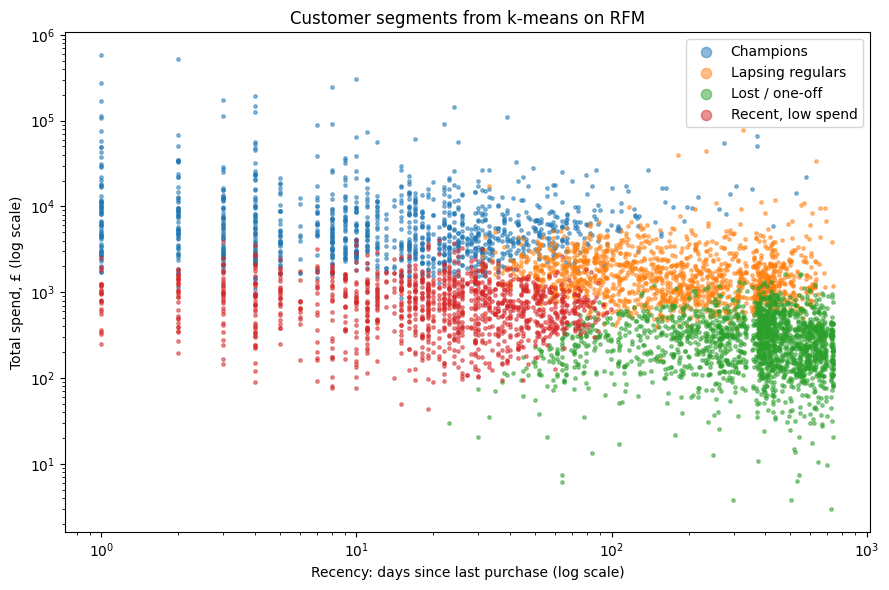

Top 20% of customers generate 77% of revenue (the Pareto principle)


In [14]:
fig, ax = plt.subplots(figsize=(9, 6))
for seg, g in rfm.groupby('Segment'):
    ax.scatter(g['Recency'], g['Monetary'], s=6, alpha=0.5, label=seg)
ax.set_xscale('log'); ax.set_yscale('log')
ax.set_xlabel('Recency: days since last purchase (log scale)'); ax.set_ylabel('Total spend, £ (log scale)')
ax.set_title('Customer segments from k-means on RFM')
ax.legend(markerscale=3)
plt.tight_layout(); plt.savefig('segments.png', dpi=150); plt.show()

top20 = rfm['Monetary'].sort_values(ascending=False)
share_top20 = top20.iloc[:int(len(top20) * 0.2)].sum() / top20.sum()
print(f'Top 20% of customers generate {share_top20:.0%} of revenue (the Pareto principle)')

## Step 7: Customer lifetime value (12 months)
**Customer lifetime value (CLV)** = how much a customer spends over a period. We use **actual** spend in each customer's first 12 months, only for customers whose full 12 months are inside the data (first purchase by Dec 2010).
The retailer's margins are not in the data, so this is revenue CLV, not profit.

In [15]:
first_date = sales.groupby('CustomerID')['InvoiceDate'].min().rename('FirstDate')
s2 = sales.join(first_date, on='CustomerID')
window = s2[s2['InvoiceDate'] < s2['FirstDate'] + pd.DateOffset(months=12)]       # first 12 months only
eligible = first_date[first_date < pd.Timestamp('2010-12-01')].index                 # full 12 months observed
clv = window[window['CustomerID'].isin(eligible)].groupby('CustomerID')['Revenue'].sum()
first_order = s2[s2['InvoiceDate'] == s2['FirstDate']].groupby('CustomerID')['Revenue'].sum()

clv_table = pd.DataFrame({'12-month CLV': clv}).join(rfm['Segment'])
clv_seg = clv_table.groupby('Segment')['12-month CLV'].agg(['count', 'median', 'mean'])
print(f'Customers with a full 12-month window: {len(clv):,}')
print(f'Median 12-month CLV: £{clv.median():,.0f} | mean: £{clv.mean():,.0f} (the mean is pulled up by large wholesale buyers)')
print(f'Median first order: £{first_order.loc[eligible].median():,.0f}, so in 12 months a typical customer spends {clv.median()/first_order.loc[eligible].median():.1f}x their first order')
clv_seg

Customers with a full 12-month window: 4,239
Median 12-month CLV: £861 | mean: £2,306 (the mean is pulled up by large wholesale buyers)
Median first order: £294, so in 12 months a typical customer spends 2.9x their first order


,count,median,mean
Segment,,,
Champions,1082,"3,087.06","6,363.38"
Lapsing regulars,1312,"1,220.90","1,630.79"
Lost / one-off,1358,284.45,324.77
"Recent, low spend",487,549.29,635.27


## Step 8: Forecast monthly revenue for the next 6 months
We compare two simple, explainable methods and **test them on data they have not seen** (a backtest):
1. **Seasonal naive with growth**: same month last year x recent year-on-year growth
2. **Holt-Winters exponential smoothing**: a classic statistical model with trend and seasonality

**Backtest:** train up to May 2011, forecast Jun-Nov 2011, compare with actual. We measure **MAPE** (mean absolute percentage error): lower is better.
December 2011 is excluded because the data stops on 9 December.

In [16]:
from statsmodels.tsa.holtwinters import ExponentialSmoothing
ts = sales.groupby('Month')['Revenue'].sum()
ts.index = pd.PeriodIndex(ts.index, freq='M').to_timestamp()
ts = ts[ts.index < '2011-12-01']                                       # drop partial December 2011
print(f'{len(ts)} full months: {ts.index[0]:%b %Y} to {ts.index[-1]:%b %Y}')

def seasonal_naive_growth(history, horizon):
    growth = history[-6:].sum() / history[-18:-12].sum()             # last 6 months vs same 6 months a year before
    base = history[-12:].values[:horizon]                            # the same months one year earlier
    idx = pd.date_range(history.index[-1] + pd.offsets.MonthBegin(1), periods=horizon, freq='MS')
    return pd.Series(base * growth, index=idx)

def holt_winters(history, horizon):
    model = ExponentialSmoothing(history, trend='add', seasonal='mul', seasonal_periods=12,
                                 initialization_method='estimated').fit()
    return model.forecast(horizon)

train, test = ts[ts.index < '2011-06-01'], ts[ts.index >= '2011-06-01']
mape = lambda f: (abs(f.values - test.values) / test.values).mean()
bt = {'Seasonal naive with growth': seasonal_naive_growth(train, len(test))}
try:
    bt['Holt-Winters'] = holt_winters(train, len(test))     # needs 2 full years; may fail on 18 months
except Exception as e:
    print('Holt-Winters backtest not possible with 18 months of training data:', type(e).__name__)
backtest = pd.DataFrame({'Actual': test, **{k: v.values for k, v in bt.items()}})
print('\nBacktest MAPE:', ' | '.join(f'{k}: {mape(v):.1%}' for k, v in bt.items()))
backtest

24 full months: Dec 2009 to Nov 2011
Holt-Winters backtest not possible with 18 months of training data: ValueError

Backtest MAPE: Seasonal naive with growth: 11.7%


,Actual,Seasonal naive with growth
Month,,
2011-06-01,"653,264.92","578,128.36"
2011-07-01,"591,603.79","534,620.95"
2011-08-01,"635,514.38","546,640.48"
2011-09-01,"938,752.63","740,619.17"
2011-10-01,"1,002,326.56","930,026.88"
2011-11-01,"1,136,534.00","1,062,808.36"


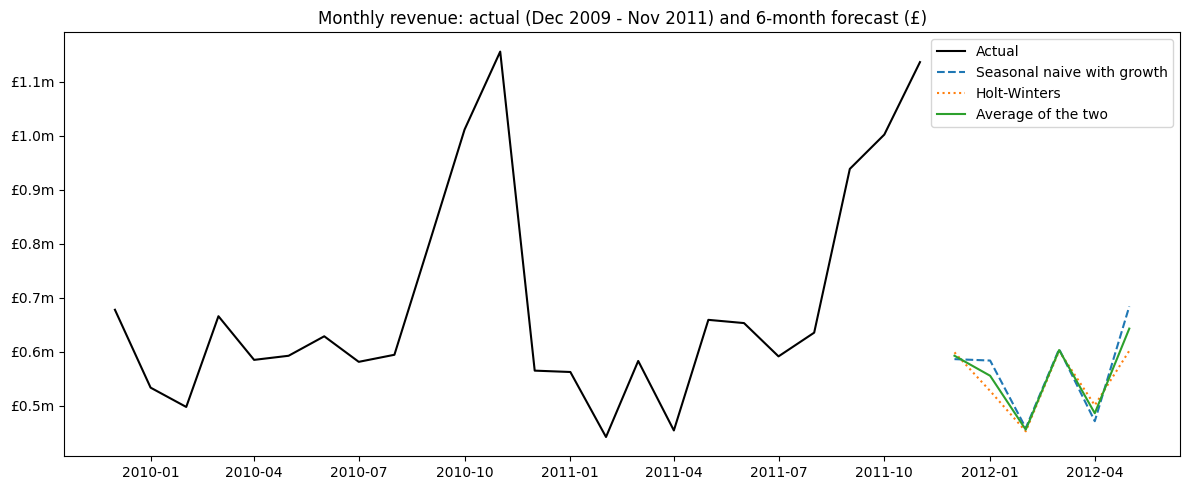

,Seasonal naive with growth,Holt-Winters,Average of the two
2011-12-01,"586,499.25","599,047.34","592,773.29"
2012-01-01,"583,887.76","527,536.24","555,712.00"
2012-02-01,"458,961.53","452,841.65","455,901.59"
2012-03-01,"605,119.77","601,615.49","603,367.63"
2012-04-01,"471,566.60","501,020.88","486,293.74"
2012-05-01,"684,086.21","601,995.93","643,041.07"


In [17]:
H = 6
fc_sn = seasonal_naive_growth(ts, H)
fc_hw = holt_winters(ts, H)
forecast = pd.DataFrame({'Seasonal naive with growth': fc_sn, 'Holt-Winters': fc_hw.values}, index=fc_sn.index)
forecast['Average of the two'] = forecast.mean(axis=1)
forecast.to_csv('revenue_forecast.csv')

fig, ax = plt.subplots(figsize=(12, 5))
ax.plot(ts.index, ts.values, color='black', label='Actual')
for col, style in zip(forecast.columns, ['--', ':', '-']):
    ax.plot(forecast.index, forecast[col], style, label=col)
ax.set_title('Monthly revenue: actual (Dec 2009 - Nov 2011) and 6-month forecast (£)')
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f'£{v/1e6:.1f}m'))
ax.legend(); plt.tight_layout(); plt.savefig('revenue_forecast.png', dpi=150); plt.show()
forecast

## Step 9: Save results
Downloads one zip file with every table and chart. Send it to Claude to write up the findings.

In [18]:
monthly.to_csv('sql_monthly.csv', index=False); top_products.to_csv('sql_top_products.csv', index=False)
countries.to_csv('sql_countries.csv', index=False); repeat.to_csv('sql_repeat_customers.csv', index=False)
ret_rate.to_csv('sql_return_rates.csv', index=False); top_net.to_csv('sql_top_products_net.csv', index=False); retention.to_csv('cohort_retention.csv')
repeat_rate.to_csv('monthly_repeat_rate.csv'); clv_seg.to_csv('clv_by_segment.csv'); backtest.to_csv('forecast_backtest.csv')
summary = pd.Series({'clean_rows': len(sales), 'customers': sales.CustomerID.nunique(), 'revenue': sales.Revenue.sum(),
                     'overall_return_rate': overall_return_rate, 'avg_monthly_repeat_rate': repeat_rate['Repeat rate'].mean(),
                     'retention_m1': avg_ret[1], 'retention_m3': avg_ret[3], 'retention_m6': avg_ret[6], 'retention_m12': avg_ret[12],
                     'top20_revenue_share': share_top20, 'median_clv_12m': clv.median(), 'mean_clv_12m': clv.mean()})
summary.to_csv('summary.csv')
print(summary.to_string())
!zip -q project4_results.zip *.csv *.png
from google.colab import files
files.download('project4_results.zip')

clean_rows                   776,577.00
customers                      5,852.00
revenue                   17,068,567.97
overall_return_rate                0.04
avg_monthly_repeat_rate            0.24
retention_m1                       0.21
retention_m3                       0.22
retention_m6                       0.18
retention_m12                      0.18
top20_revenue_share                0.77
median_clv_12m                   861.01
mean_clv_12m                   2,306.01


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## Step 10: Findings
Period: Dec 2009 to Nov 2011 (Dec 2011 is partial). Clean data: 776,577 sales lines, 5,852 customers, £17.07m revenue.

1. **Repeat customers are the business.** 72% of customers ordered more than once, and they generated **97% of revenue**. One-time buyers (28% of customers) brought just 3%.
2. **Revenue is highly concentrated.** The top 20% of customers produced **77% of revenue**. k-means found a "Champions" segment (20% of customers, median 13 orders, last purchase 16 days ago) that alone brought **73% of revenue**.
3. **A quarter of customers are slipping away.** The "Lapsing regulars" segment (25% of customers, 17% of revenue) used to order regularly (median 4 orders) but had not bought for a median of 184 days, the obvious target for a win-back campaign.
4. **Retention is stable at about one in five.** On average 21% of a cohort bought again 1 month after their first purchase, and 18% were still buying 12 months later. The monthly repeat purchase rate fell from about 30% of past customers in 2010 to about 18% in 2011, as the base grew with customers who had stopped buying.
5. **Lifetime value:** median 12-month revenue per customer was **£861** (mean £2,306, pulled up by large wholesale buyers); Champions' median was £3,087.
6. **The SQL returns query caught a data problem.** Two top-10 "best sellers" (a paper craft item and a storage jar) had **95-100% of their sales cancelled**, single bulk orders that were reversed. Ranking products net of returns (Query 6) removes them. Overall, returned value was 4.2% of sales.
7. **Strong year-end seasonality, flat underlying sales.** Sept-Nov brings the peak (Nov 2011: £1.14m vs about £0.6m in a normal month). Year-on-year, revenue was flat: £8.33m (Dec 2009 - Nov 2010) vs £8.23m (Dec 2010 - Nov 2011).
8. **Forecast:** about **£3.34m for Dec 2011 - May 2012** (average of the two methods). In the backtest the seasonal method was off by **11.7% on average (MAPE) and under-forecast every month**, missing the strength of autumn 2011, so the forecast is likely conservative.

## Limitations
- One UK retailer selling giftware, mostly to small wholesale buyers, so results are not typical of a consumer beauty brand.
- About a fifth of rows have no customer ID and are excluded from customer analysis.
- No cost or margin data: lifetime value is revenue, not profit.
- Two years of data give only one full seasonal cycle to test against; Holt-Winters could not be backtested.
- k-means needs the number of segments to be chosen; the elbow and silhouette charts guide, but do not decide, that choice.